# L7. Backtracking for CSPs - Asterisk_Sudoku

## CSPs Recall

CSPs are a special kind of search problems. Here we don't treat the space as a black box but the state has a particular form and we use that to our advantage to tweak our algorithms to be more suited to the problems.

A CSP State is defined by a set of variables which can take values from corresponding domains. These variables can take only certain values in their domains to satisfy the constraints.

A set of assignments which satisfies all constraints passes the goal test.

A **CSP is specified by** the following **inputs**:

* **variables** - A list of variables; each is atomic (e.g. int or string).
* **domains** - A dict of {var:[possible_value, ...]} entries.
* **neighbors** - A dict of {var:[var,...]} that for each variable lists the other variables that participate in constraints.
* **constraints** - A function f(A, a, B, b) that returns true if neighbors A, B satisfy the constraint when they have values A=a, B=b

Since "CSPs are a special kind of search problems" our `CSPBasic class` is a derived class from the `base Problem class`.

A `CSPBasic class` consists of all is CSP's inputs mentioned above.

The `__ _ init _ __` method parameters specify the CSP.

* `Variables` can be passed as a list of strings or integers.

* `Domains` are passed as dict where "key" specifies the variables and "value" specifies the domains.

The variables are passed as an empty list. Variables are extracted from the keys of the domain dictionary.

* `Neighbor` is a dict of variables that essentially describes the constraint graph. Here each variable key has a list of its values which are the variables that are constraint along with it.

* The `constraint parameter` should be a function *f(A, a, B, b)* that returns true if neighbors A, B satisfy the constraint when they have values A=a, B=b.

* We have additional parameters like `nassings` which is incremented each time an assignment is made when calling the `assign` method.

The `CSPBasic class` also supports data structures and methods that help you solve CSPs by calling a search function on the CSP.

In [1]:
from src.CSPclass import CSPBasic

In [2]:
help(CSPBasic.prune)

Help on function prune in module src.CSPclass:

prune(self, var, value)
    Rule out var=value.



In [3]:
help(CSPBasic.__init__)

Help on function __init__ in module src.CSPclass:

__init__(self, variables, domains, neighbors, constraints)
    Construct a CSP problem. If variables is empty, it becomes domains.keys().



Also we need to create the `CSP class` derived from `CSPBAsic`

In [4]:
from src.CSPclass import CSP

In [5]:
help(CSP.assign)

Help on function assign in module src.CSPclass:

assign(self, var, val, assignment)
    Add {var: val} to assignment; Discard the old value if any.



In [6]:
help(CSP.unassign)

Help on function unassign in module src.CSPclass:

unassign(self, var, assignment)
    Remove {var: val} from assignment.
    DO NOT call this if you are changing a variable to a new value;
    just call assign for that.



In [7]:
help(CSP.display)

Help on function display in module src.CSPclass:

display(self, assignment)
    Show a human-readable representation of the CSP.



## Australia map-coloring problem example

The idea of `map coloring problem` is that the adjacent nodes (those connected by edges) should not have the same color throughout the graph.

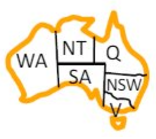

The graph can be colored using a fixed number of colors.

Here *each node* is a *variable* and the values are the colors that can be assigned to them.

Given that **the domain will be the same for all our nodes** we use a custom dict defined by the UniversalDict class.

The `UniversalDict Class` takes in a parameter and returns it as a value for all the keys of the dict.

It does not support item assignment.

A `universal dict` maps any key to the same value. 

We use it here as the domains dict for CSPs in which all variables have the same domain.

In [8]:
from src.utils import UniversalDict

In [9]:
d = UniversalDict(list('RGB'))

In [10]:
d['SA']

['R', 'G', 'B']

In [11]:
print(d)

Any from ['R', 'G', 'B']


In [12]:
australiaColors=UniversalDict(list('RGB'))

In [13]:
print(australiaColors['SA'],australiaColors['NT'])

['R', 'G', 'B'] ['R', 'G', 'B']


**!!!** remember: Our CSP Class includes the constraint parameter which should be a function f(A, a, B, b)

So, we need to define a constraint function *f(A, a, B, b)*.

In this case , we need to ensure that **the neighbors don't have the same color**

This is defined in the function `different_values_constraint` of the module `Utils.py`

In [14]:
from src.utils import different_values_constraint
help(different_values_constraint)

Help on function different_values_constraint in module src.utils:

different_values_constraint(A, a, B, b)
    A constraint saying two neighboring variables must differ in value.



The `CSP class` takes `neighbors` in the form of a *Dictionary*.

`{'Y': ['X', 'Z'], 'X': ['Y', 'Z'], 'Z': ['X', 'Y']}`

A simple helper function `parse_neighbors `allows us to take input in the form of strings and return a Dict of a form that is compatible with the CSP Class.

In [15]:
from src.utils import parse_neighbors
help(parse_neighbors)

Help on function parse_neighbors in module src.utils:

parse_neighbors(neighbors)
    Convert a string of the form 'X: Y Z; Y: Z' into a dict mapping
    regions to neighbors. The syntax is a region name followed by a ':'
    followed by zero or more region names, followed by ';', repeated for
    each region name. If you say 'X: Y' you don't need 'Y: X'.
    >>> parse_neighbors('X: Y Z; Y: Z') == {'Y': ['X', 'Z'], 'X': ['Y', 'Z'], 'Z': ['X', 'Y']}
    True



In [16]:
australia="SA: WA NT Q NSW V; NT: WA Q; NSW: Q V; T: "

In [17]:
parse_neighbors(australia)

defaultdict(list,
            {'SA': ['WA', 'NT', 'Q', 'NSW', 'V'],
             'WA': ['SA', 'NT'],
             'NT': ['SA', 'WA', 'Q'],
             'Q': ['SA', 'NT', 'NSW'],
             'NSW': ['SA', 'Q', 'V'],
             'V': ['SA', 'NSW']})

The `MapColoringCSP` function creates and returns a CSP with the above constraint function and states.

In [18]:
from src.CSPS import MapColoringCSP
help(MapColoringCSP)

Help on function MapColoringCSP in module src.CSPS:

MapColoringCSP(colors, neighbors)
    Make a CSP for the problem of coloring a map with different colors
    for any two adjacent regions. Arguments are a list of colors, and a
    dict of {region: [neighbor,...]} entries. This dict may also be
    specified as a string of the form defined by parse_neighbors.



In [19]:
australiaCSP = MapColoringCSP(list('RGB'), australia)

In [20]:
australiaCSP.variables

['SA', 'WA', 'NT', 'Q', 'NSW', 'V']

In [21]:
australiaCSP.domains

Any from ['R', 'G', 'B']

In [22]:
australiaCSP.neighbors

defaultdict(list,
            {'SA': ['WA', 'NT', 'Q', 'NSW', 'V'],
             'WA': ['SA', 'NT'],
             'NT': ['SA', 'WA', 'Q'],
             'Q': ['SA', 'NT', 'NSW'],
             'NSW': ['SA', 'Q', 'V'],
             'V': ['SA', 'NSW']})

## Backtracking Search

In backtracking search, we check the constraints as we go and we deal with only one variable at a time

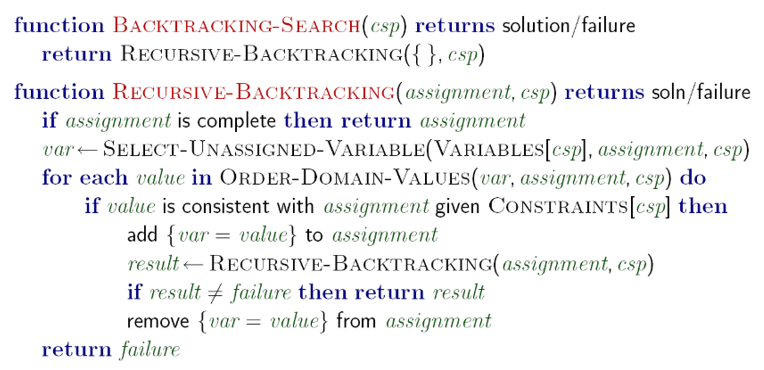

The algorithm searches **a tree of partial assignments**.

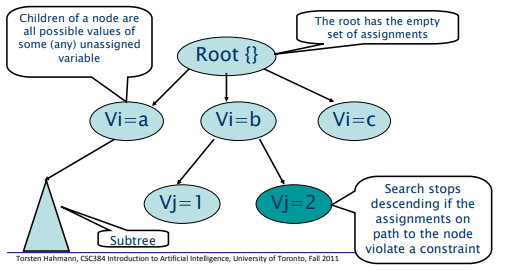

Backtracking example for Australia map-coloring

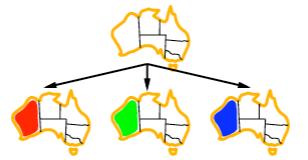

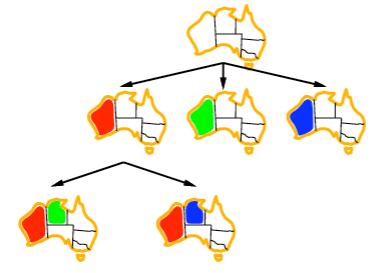

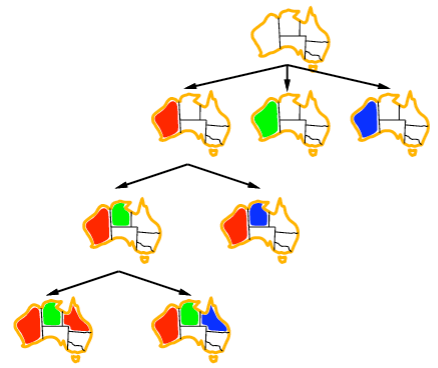


In [23]:
from src.algorithms import backtracking_search

In [24]:
result = backtracking_search(australiaCSP)

In [25]:
result

{'SA': 'R', 'WA': 'G', 'NT': 'B', 'Q': 'G', 'NSW': 'B', 'V': 'G'}

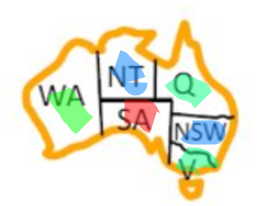

And resolve it with AC-3:

## Tasks

### Task 1. The Dinner Accomodation Problem - 25 points

Five colleagues (designated A, B, C, D, E) are planning to go to dinner but they don’t all get along.

Specifically:
* A despises B
* B always argues with E
* C is B's manager, so B does not want to be subject to the extra scrutiny of sitting next to C.

You need to place them around a dining table with 6 chairs to avoid any potential problems.

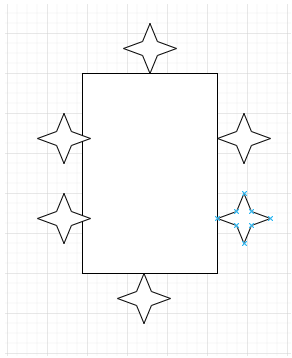

Tasks: (1-5 -> 15 points, 6-> 3 points, 7->2 points, 8->3 points, 9->2 points)

1. Formulate the problem (presented above) as a CSP problem.
2. Develop CSP implementation (based on CSP class)
3. Visualize the constraints graph with PyVis
4. After running constraint propagation once without search, do any of the domains change? (Apply AC-3 for the answer). 
5. Apply a backtracking search algorithm to solve ths problem
6. Visualize the process of chairs assignment as a web-service with Streamlit 

7. Improve backtracking search using Minimum Remaining Values (MRV).

Modify your backtracking implementation to use the MRV heuristic for variable ordering.
- Select the unassigned variable with the smallest remaining domain.
- Apply MRV when choosing which variable to assign next.
- Solve the Dinner Accommodation Problem using MRV.
- Compare the results with the basic backtracking algorithm.
- Record and compare the number of search nodes or variable assignments explored.

8. Improve variable ordering using MRV + Degree Heuristic.

Extend Task 7 by combining MRV with the Degree Heuristic.
- First, select the unassigned variable with the fewest remaining legal values (MRV).
- If multiple variables have the same number of remaining values, use the Degree Heuristic as a tie-breaker.
- Select the variable that is involved in constraints with the largest number of other unassigned variables.
- Solve the problem using the combined heuristic.
- Compare the search performance with basic backtracking and MRV.

9. Modify your backtracking implementation to use the Least Constraining Value (LCV) heuristic
* Implement LCV to select the value that eliminates the fewest possible values from the domains of neighboring unassigned variables.
* Apply LCV when deciding which chair to assign to a selected colleague.
* Solve the Dinner Accommodation Problem using LCV.
* Compare the results with basic backtracking.
* Record and compare the number of search nodes or variable assignments explored.

For Tasks 7, 8 and 9, you should use the same CSP formulation and compare the number of search nodes explored. This makes the impact of the Heuristics measurable rather than simply comparing whether they find a solution.

---
## Task 1 - Solution

> All code written for this lab is marked **[Lab7 added]** / **[Lab7 changed]** in the `src` files:
> * `src/CSPS.py` → `DinnerCSP` class (Task 1) and `AsteriskSudokuCSP` (Task 2)
> * `src/algorithms.py` → heuristics `mrv`, `mrv_degree`, `lcv`, node counters and a step trace in `backtracking_search`, `verbose` flag for `AC3`
> * `src/cspVisualization.py` → PyVis drawing of the constraint graph
> * `dinner_app.py`, `sudoku_app.py` → Streamlit web-services

### 1.1 Formulating the problem as a CSP

The table from the picture has 6 chairs. I number them **clockwise starting at the top**:

```
              [1]
       +-------------+
   [6] |             | [2]
       |    TABLE    |
   [5] |             | [3]
       +-------------+
              [4]
```

The chairs form a ring 1-2-3-4-5-6-1, so two chairs are *next to each other* when they are consecutive on the ring (chair 6 is next to chair 1).

| CSP part | Dinner problem |
|---|---|
| **Variables** | the colleagues `A, B, C, D, E` |
| **Domains** | the chairs `{1, 2, 3, 4, 5, 6}` - the same for everybody (`UniversalDict`) |
| **Constraints** | **(1) AllDifferent** - nobody shares a chair → binary constraint `a != b` between every pair<br>**(2) Not adjacent** for the conflicting pairs: `A–B` (A despises B), `B–E` (B argues with E), `B–C` (C is B's manager) |
| **Neighbors** | because of AllDifferent every person is a neighbor of every other person (complete graph K5); the pairs A–B, B–E, B–C carry the extra "not adjacent" constraint |

The constraint function `f(A, a, B, b)`:
* returns `False` if `a == b` (same chair)
* returns `False` if `{A, B}` is a conflicting pair and chairs `a`, `b` are adjacent
* otherwise returns `True`

### 1.2 CSP implementation (based on the `CSP` class)

`DinnerCSP` in `src/CSPS.py` is a **subclass of `CSP`**. It only adds the constraint function `dinner_constraint`, a `display` method that draws the table, and `num_constraints(X, Y)` (used by the Degree heuristic in Task 8).

In [26]:
# Import the Task 1 CSP and helper functions written in src/CSPS.py
from src.CSPS import DinnerCSP, DINNER_CONFLICTS, chairs_adjacent, check_dinner_solution
help(DinnerCSP.dinner_constraint)

Help on function dinner_constraint in module src.CSPS:

dinner_constraint(self, A, a, B, b)
    f(A, a, B, b): True when person A on chair a and person B on
    chair b are compatible.



In [27]:
# Create the CSP and look at its 4 inputs
dinnerCSP = DinnerCSP()

print("Variables :", dinnerCSP.variables)
print("Domains   :", dinnerCSP.domains)            # UniversalDict -> same chairs for everybody
print("Neighbors :")
for person, neigh in dinnerCSP.neighbors.items():
    print(f"   {person}: {neigh}")
print("Conflicting pairs (must NOT be adjacent):")
for pair, reason in DINNER_CONFLICTS.items():
    print(f"   {sorted(pair)} -> {reason}")

Variables : ['A', 'B', 'C', 'D', 'E']
Domains   : Any from [1, 2, 3, 4, 5, 6]
Neighbors :
   A: ['B', 'C', 'D', 'E']
   B: ['A', 'C', 'D', 'E']
   C: ['A', 'B', 'D', 'E']
   D: ['A', 'B', 'C', 'E']
   E: ['A', 'B', 'C', 'D']
Conflicting pairs (must NOT be adjacent):
   ['A', 'B'] -> A despises B
   ['B', 'E'] -> B argues with E
   ['B', 'C'] -> C is B's manager


In [28]:
# Quick check of the constraint function f(A, a, B, b)
tests = [('A', 1, 'B', 1),   # same chair                 -> False
         ('A', 1, 'B', 2),   # A, B enemies and adjacent  -> False
         ('A', 1, 'B', 6),   # 6 and 1 are adjacent too   -> False (ring!)
         ('A', 1, 'B', 3),   # enemies but not adjacent   -> True
         ('A', 1, 'D', 2)]   # not enemies, adjacent      -> True
for t in tests:
    print(t, "->", dinnerCSP.constraints(*t))

('A', 1, 'B', 1) -> False
('A', 1, 'B', 2) -> False
('A', 1, 'B', 6) -> False
('A', 1, 'B', 3) -> True
('A', 1, 'D', 2) -> True


### 1.3 Constraint graph with PyVis

Grey edges = only "different chairs". **Red** edges = "different chairs" **and** "not next to each other" (the label says why). Red nodes are the people involved in a conflict. Hover a node to see its domain.

In [29]:
# Draw the constraint graph -> task1_dinner_constraints.html (main project folder)
from src.cspVisualization import visualize_dinner_csp
from IPython.display import IFrame

visualize_dinner_csp(dinnerCSP, "task1_dinner_constraints.html")
IFrame("task1_dinner_constraints.html", width="100%", height=620)

### 1.4 Constraint propagation once, without search (AC-3)

In [30]:
# Run AC-3 on a fresh CSP (verbose=True prints every arc as in the tutorial)
from src.algorithms import AC3

ac3CSP = DinnerCSP()
print("Domains BEFORE AC-3:", {v: list(ac3CSP.domains[v]) for v in ac3CSP.variables})
consistent, checks = AC3(ac3CSP)
print()
print("Consistent:", consistent, "| constraint checks:", checks)
print("Domains AFTER AC-3 :", ac3CSP.curr_domains)

Domains BEFORE AC-3: {'A': [1, 2, 3, 4, 5, 6], 'B': [1, 2, 3, 4, 5, 6], 'C': [1, 2, 3, 4, 5, 6], 'D': [1, 2, 3, 4, 5, 6], 'E': [1, 2, 3, 4, 5, 6]}
Initial queue:
('A', 'B') ('A', 'C') ('A', 'D') ('A', 'E') 
('B', 'A') ('B', 'C') ('B', 'D') ('B', 'E') 
('C', 'A') ('C', 'B') ('C', 'D') ('C', 'E') 
('D', 'A') ('D', 'B') ('D', 'C') ('D', 'E') 
('E', 'A') ('E', 'B') ('E', 'C') ('E', 'D') 
Arc ('A', 'B') is cheking
Queue: [('A', 'C'), ('A', 'D'), ('A', 'E'), ('B', 'A'), ('B', 'C'), ('B', 'D'), ('B', 'E'), ('C', 'A'), ('C', 'B'), ('C', 'D'), ('C', 'E'), ('D', 'A'), ('D', 'B'), ('D', 'C'), ('D', 'E'), ('E', 'A'), ('E', 'B'), ('E', 'C'), ('E', 'D')]
Arc ('A', 'C') is cheking
Queue: [('A', 'D'), ('A', 'E'), ('B', 'A'), ('B', 'C'), ('B', 'D'), ('B', 'E'), ('C', 'A'), ('C', 'B'), ('C', 'D'), ('C', 'E'), ('D', 'A'), ('D', 'B'), ('D', 'C'), ('D', 'E'), ('E', 'A'), ('E', 'B'), ('E', 'C'), ('E', 'D')]
Arc ('A', 'D') is cheking
Queue: [('A', 'E'), ('B', 'A'), ('B', 'C'), ('B', 'D'), ('B', 'E'), ('C', '

In [31]:
# Did any domain change? Compare each domain before and after AC-3
changed = {v: sorted(set(ac3CSP.domains[v]) - set(ac3CSP.curr_domains[v]))
           for v in ac3CSP.variables}
print("Values removed by AC-3:", changed)
print("Any domain changed?   ", any(changed.values()))

Values removed by AC-3: {'A': [], 'B': [], 'C': [], 'D': [], 'E': []}
Any domain changed?    False


**Answer: No, no domain changes.** Every person keeps all 6 chairs.

AC-3 removes a value only when it has **no support** in a neighbor's domain. Take B, the most constrained person: whatever chair B picks, A (or C, or E) can still pick a chair that is different and not adjacent. For example, B = 1 is supported by A = 3, 4 or 5. With 6 free chairs, every value of every variable always has support, so propagation alone cannot reduce anything. Search is needed.

### 1.5 Backtracking search (basic)

Basic = `first_unassigned_variable` + `unordered_domain_values` (the tutorial's defaults). After the search, `nassigns`, `nodes_explored` and `nbacktracks` are stored on the CSP object (counters added in `src/algorithms.py`).

In [32]:
from src.algorithms import backtracking_search

basicCSP = DinnerCSP()                         # fresh CSP -> counters start at 0
basicResult = backtracking_search(basicCSP)    # default heuristics = basic backtracking

print("Solution        :", basicResult)
print("Valid?          :", check_dinner_solution(basicCSP, basicResult))
print("Assignments     :", basicCSP.nassigns)
print("Nodes explored  :", basicCSP.nodes_explored)
print("Backtracks      :", basicCSP.nbacktracks)
print()
basicCSP.display(basicResult)

Solution        : {'A': 1, 'B': 3, 'C': 5, 'D': 2, 'E': 6}
Valid?          : True
Assignments     : 5
Nodes explored  : 6
Backtracks      : 0

            [1: A]
   [6: E]              [2: D]
   [5: C]              [3: B]
            [4:--]


In [33]:
# The same search with a recorded trace, to see every step it takes
from src.algorithms import replay_trace

trace = []
backtracking_search(DinnerCSP(), trace=trace)
for i, (action, var, value) in enumerate(trace, 1):
    print(f"{i:2}. {action:9} {var or ''} {value or ''}")

 1. assign    A 1
 2. conflict  B 1
 3. conflict  B 2
 4. assign    B 3
 5. conflict  C 1
 6. conflict  C 2
 7. conflict  C 3
 8. conflict  C 4
 9. assign    C 5
10. conflict  D 1
11. assign    D 2
12. conflict  E 1
13. conflict  E 2
14. conflict  E 3
15. conflict  E 4
16. conflict  E 5
17. assign    E 6
18. solution   


### 1.6 Streamlit web-service

The step-by-step chair assignment is visualised in **`dinner_app.py`** (main project folder). Run it from a terminal in the project folder:

```
streamlit run dinner_app.py
```

The page shows:
* the table drawn as SVG: green = seated, red = rejected value (conflict), orange = undone assignment (backtrack)
* a **Step** slider and a **Play** button to watch the search
* a sidebar to choose the variable ordering (basic / MRV / MRV+Degree), the value ordering (basic / LCV) and the order of `csp.variables`
* the metrics (assignments, nodes, backtracks), the search log, and a comparison table of all heuristics

### 1.7 MRV - Minimum Remaining Values

`mrv(assignment, csp)` in `src/algorithms.py` picks the unassigned variable with the **fewest legal values** left. A value is legal if `csp.nconflicts(var, value, assignment) == 0`. This is the "fail-first" idea: the most constrained person is seated first.

In [34]:
from src.algorithms import mrv, num_legal_values

# Example: after A sits on chair 1, how many legal chairs does everybody else have?
example = {'A': 1}
print({v: num_legal_values(dinnerCSP, v, example) for v in dinnerCSP.variables if v not in example})
print("MRV picks:", mrv(example, dinnerCSP), "(B lost chairs 1, 2 and 6)")

{'B': 3, 'C': 5, 'D': 5, 'E': 5}
MRV picks: B (B lost chairs 1, 2 and 6)


In [35]:
mrvCSP = DinnerCSP()
mrvResult = backtracking_search(mrvCSP, select_unassigned_variable=mrv)

print("Solution        :", mrvResult, "| valid:", check_dinner_solution(mrvCSP, mrvResult))
print("Assignments     :", mrvCSP.nassigns)
print("Nodes explored  :", mrvCSP.nodes_explored)
print("Backtracks      :", mrvCSP.nbacktracks)
mrvCSP.display(mrvResult)

Solution        : {'A': 1, 'B': 3, 'C': 5, 'E': 6, 'D': 2} | valid: True
Assignments     : 5
Nodes explored  : 6
Backtracks      : 0
            [1: A]
   [6: E]              [2: D]
   [5: C]              [3: B]
            [4:--]


### 1.8 MRV + Degree heuristic

`mrv_degree(assignment, csp)` sorts the unassigned variables by
1. fewest legal values (MRV), then
2. **most constraints with other unassigned variables** (Degree) as the tie-breaker.

Each pair of people has the AllDifferent constraint, and the pairs A–B, B–E, B–C have a second "not adjacent" constraint. `DinnerCSP.num_constraints(X, Y)` returns 1 or 2, and `degree()` adds them up over the unassigned neighbors. At the start all 5 people tie on MRV (6 chairs each), so Degree decides, and **B goes first** (degree 7).

In [36]:
from src.algorithms import mrv_degree, degree

print("Degree at the start:", {v: degree(dinnerCSP, v, {}) for v in dinnerCSP.variables})
print("MRV + Degree picks first:", mrv_degree({}, dinnerCSP))

mrvDegCSP = DinnerCSP()
mrvDegResult = backtracking_search(mrvDegCSP, select_unassigned_variable=mrv_degree)

print()
print("Solution        :", mrvDegResult, "| valid:", check_dinner_solution(mrvDegCSP, mrvDegResult))
print("Assignments     :", mrvDegCSP.nassigns)
print("Nodes explored  :", mrvDegCSP.nodes_explored)
print("Backtracks      :", mrvDegCSP.nbacktracks)
mrvDegCSP.display(mrvDegResult)

Degree at the start: {'A': 5, 'B': 7, 'C': 5, 'D': 4, 'E': 5}
MRV + Degree picks first: B

Solution        : {'B': 1, 'A': 3, 'C': 4, 'E': 5, 'D': 2} | valid: True
Assignments     : 5
Nodes explored  : 6
Backtracks      : 0
            [1: B]
   [6:--]              [2: D]
   [5: E]              [3: A]
            [4: C]


### 1.9 LCV - Least Constraining Value

`lcv(var, assignment, csp)` sorts the chairs of the selected person by **how many still-legal chairs they would take away** from the unassigned neighbors. The chair that removes the fewest is tried first.

Only chairs that are still legal for a neighbor are counted, because a chair that is already impossible cannot be "taken away" again. This is what makes LCV useful here: chairs next to B's enemies are useless for B, so LCV seats the other people there first and keeps the chairs B could use free.

In [37]:
from src.algorithms import lcv

# Example: A is on chair 1 and D is the next person to seat.
# For each LEGAL chair of D, count how many still-legal chairs it takes away from B, C, E
example = {'A': 1}
for chair in dinnerCSP.choices('D'):
    if dinnerCSP.nconflicts('D', chair, example) == 0:
        removed = sum(1 for n in dinnerCSP.neighbors['D'] if n not in example
                      for y in dinnerCSP.choices(n)
                      if dinnerCSP.nconflicts(n, y, example) == 0
                      and not dinnerCSP.constraints('D', chair, n, y))
        print(f"D on chair {chair} removes {removed} options from B, C, E")
print("LCV order for D:", lcv('D', example, dinnerCSP))
# Chairs 2 and 6 are next to A, so B cannot use them anyway.
# Putting D there "costs" nothing for B -> LCV tries them first.

D on chair 2 removes 2 options from B, C, E
D on chair 3 removes 3 options from B, C, E
D on chair 4 removes 3 options from B, C, E
D on chair 5 removes 3 options from B, C, E
D on chair 6 removes 2 options from B, C, E
LCV order for D: [2, 6, 3, 4, 5, 1]


In [38]:
lcvCSP = DinnerCSP()
lcvResult = backtracking_search(lcvCSP, order_domain_values=lcv)

print("Solution        :", lcvResult, "| valid:", check_dinner_solution(lcvCSP, lcvResult))
print("Assignments     :", lcvCSP.nassigns)
print("Nodes explored  :", lcvCSP.nodes_explored)
print("Backtracks      :", lcvCSP.nbacktracks)
lcvCSP.display(lcvResult)

Solution        : {'A': 1, 'B': 3, 'C': 5, 'D': 2, 'E': 6} | valid: True
Assignments     : 5
Nodes explored  : 6
Backtracks      : 0
            [1: A]
   [6: E]              [2: D]
   [5: C]              [3: B]
            [4:--]


### 1.10 Comparison of the heuristics (Tasks 7, 8, 9)

All runs use the **same CSP formulation** (`DinnerCSP`). Two experiments:

1. **Default variable order** `A, B, C, D, E`.
2. **All 120 possible orders** of `csp.variables`. The basic search depends heavily on this order (it is lucky with A, B, C, D, E), so averaging over every order shows the real effect of each heuristic.

In [39]:
import itertools
import pandas as pd
from src.algorithms import first_unassigned_variable, unordered_domain_values

# every strategy = (variable ordering, value ordering)
strategies = {
    "Basic backtracking": (first_unassigned_variable, unordered_domain_values),
    "MRV (Task 7)":       (mrv,                       unordered_domain_values),
    "MRV + Degree (Task 8)": (mrv_degree,             unordered_domain_values),
    "LCV (Task 9)":       (first_unassigned_variable, lcv),
}

def run(order, select, order_values):
    """Solve a fresh DinnerCSP with the given variable order and heuristics."""
    csp = DinnerCSP(people=list(order))
    result = backtracking_search(csp, select, order_values)
    assert check_dinner_solution(csp, result)      # every solution must be valid
    return csp

# ---- Experiment 1: default order A B C D E -----------------------------------
rows = []
for name, (sel, val) in strategies.items():
    csp = run("ABCDE", sel, val)
    rows.append({"strategy": name, "assignments": csp.nassigns,
                 "nodes explored": csp.nodes_explored, "backtracks": csp.nbacktracks})
print("Experiment 1 - variable order A, B, C, D, E")
pd.DataFrame(rows)

Experiment 1 - variable order A, B, C, D, E


,strategy,assignments,nodes explored,backtracks
0,Basic backtracking,5,6,0
1,MRV (Task 7),5,6,0
2,MRV + Degree (Task 8),5,6,0
3,LCV (Task 9),5,6,0


In [40]:
# ---- Experiment 2: all 120 orders of the variables ---------------------------
rows = []
for name, (sel, val) in strategies.items():
    stats = [run(order, sel, val) for order in itertools.permutations("ABCDE")]
    rows.append({"strategy": name,
                 "avg assignments": sum(c.nassigns for c in stats) / len(stats),
                 "max assignments": max(c.nassigns for c in stats),
                 "avg nodes": sum(c.nodes_explored for c in stats) / len(stats),
                 "max nodes": max(c.nodes_explored for c in stats),
                 "avg backtracks": sum(c.nbacktracks for c in stats) / len(stats),
                 "orders that needed backtracking": sum(c.nbacktracks > 0 for c in stats)})
print("Experiment 2 - averaged over all 120 variable orders")
pd.DataFrame(rows)

Experiment 2 - averaged over all 120 variable orders


,strategy,avg assignments,max assignments,avg nodes,max nodes,avg backtracks,orders that needed backtracking
0,Basic backtracking,6.0,15,7.0,16,1.0,30
1,MRV (Task 7),5.6,9,6.6,10,0.6,18
2,MRV + Degree (Task 8),5.0,5,6.0,6,0.0,0
3,LCV (Task 9),5.0,5,6.0,6,0.0,0


In [41]:
# The worst order for basic backtracking (B is placed last)
rows = []
for name, (sel, val) in strategies.items():
    csp = run("EDCAB", sel, val)
    rows.append({"strategy": name, "assignments": csp.nassigns,
                 "nodes explored": csp.nodes_explored, "backtracks": csp.nbacktracks})
print("Variable order E, D, C, A, B")
pd.DataFrame(rows)

Variable order E, D, C, A, B


,strategy,assignments,nodes explored,backtracks
0,Basic backtracking,15,16,10
1,MRV (Task 7),5,6,0
2,MRV + Degree (Task 8),5,6,0
3,LCV (Task 9),5,6,0


**Conclusions**

* With the order A, B, C, D, E every strategy needs only 5 assignments, because this order happens to seat A and B early. The default order hides the difference.
* Over all 120 orders:
  * **Basic backtracking** needs 6 assignments on average and up to 15, with 10 backtracks when B, the hardest person, is seated last.
  * **MRV** lowers the average to 5.6 and the worst case to 9. When everyone still has 6 chairs it ties, and ties fall back to the variable order, so it can still start badly.
  * **MRV + Degree** always needs exactly 5 assignments (the minimum) with 0 backtracks. Degree breaks the first tie in favour of B, the person with the most constraints.
  * **LCV** also always needs 5 assignments with 0 backtracks. Even when B comes last, the earlier people are placed on chairs that leave B a legal spot.
* The minimum possible is 5 assignments and 6 nodes (the root plus one node per person). MRV + Degree and LCV reach it for every order.

### Task 2. Asterisk Sudoku - 10 points

Tasks: (1 -> 5 points, 2-> 5 points)

1. Apply a backtracking search algorithm to solve the Asterisk Sudoku (Assignment 6)
2. Visualize the process as a web-service with Streamlit

---
## Task 2 - Solution

### 2.1 Backtracking search on the Asterisk Sudoku (Assignment 6)

`AsteriskSudokuCSP()` in `src/CSPS.py` builds the same CSP as in Assignment 6:
* **Variables:** the 81 cells `A1 … I9`
* **Domains:** a given cell → `[digit]`, an empty cell → `[1..9]`
* **Neighbors:** cells in the same row, column, 3×3 box **or** in the asterisk `B5, C3, C7, E2, E5, E8, G3, G7, H5`
* **Constraint:** neighbors must have different digits (`different_values_constraint`)

In [42]:
from src.CSPS import AsteriskSudokuCSP, print_sudoku, check_sudoku_solution, ASTERISK_CELLS
import time

sudokuCSP = AsteriskSudokuCSP()
print("Asterisk cells:", ASTERISK_CELLS)
print("Neighbors of E5 (asterisk centre):", len(sudokuCSP.neighbors['E5']))
print()
print("Puzzle:")
print_sudoku(sudokuCSP.domains)     # single-value domains = givens

Asterisk cells: ['B5', 'C3', 'C7', 'E2', 'E5', 'E8', 'G3', 'G7', 'H5']
Neighbors of E5 (asterisk centre): 24

Puzzle:
. 1 . | . . . | . 6 .
3 . 9 | . . . | 1 . 5
. 8 . | 3 . 5 | . 7 .
------+-------+------
. . 2 | . 7 . | 8 . .
. . . | 6 . 8 | . . .
. . 8 | . 9 . | 2 . .
------+-------+------
. 2 . | 4 . 1 | . 9 .
9 . 4 | . . . | 6 . 1
. 3 . | . . . | . 8 .


In [43]:
# Basic backtracking: first unassigned variable + unordered values (takes a few seconds)
basicSudoku = AsteriskSudokuCSP()
start = time.time()
sudokuSolution = backtracking_search(basicSudoku)
basicTime = time.time() - start

print_sudoku(sudokuSolution)
print()
print("Valid solution (rows, cols, boxes, asterisk)?", check_sudoku_solution(sudokuSolution))
print("Asterisk digits:", sorted(sudokuSolution[c] for c in ASTERISK_CELLS))
print(f"Assignments: {basicSudoku.nassigns:,} | nodes: {basicSudoku.nodes_explored:,} | "
      f"backtracks: {basicSudoku.nbacktracks:,} | time: {basicTime:.1f}s")

2 1 5 | 7 4 9 | 3 6 8
3 7 9 | 2 8 6 | 1 4 5
4 8 6 | 3 1 5 | 9 7 2
------+-------+------
1 9 2 | 5 7 4 | 8 3 6
5 4 3 | 6 2 8 | 7 1 9
7 6 8 | 1 9 3 | 2 5 4
------+-------+------
8 2 7 | 4 6 1 | 5 9 3
9 5 4 | 8 3 7 | 6 2 1
6 3 1 | 9 5 2 | 4 8 7

Valid solution (rows, cols, boxes, asterisk)? True
Asterisk digits: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Assignments: 316,619 | nodes: 316,620 | backtracks: 316,538 | time: 5.8s


In [44]:
# For comparison: the same search after AC-3, and with the MRV / MRV+Degree heuristics
rows = [{"strategy": "Basic backtracking", "assignments": basicSudoku.nassigns,
         "nodes": basicSudoku.nodes_explored, "backtracks": basicSudoku.nbacktracks,
         "time (s)": round(basicTime, 2)}]

for name in ["AC-3 + basic", "MRV", "MRV + Degree"]:
    csp = AsteriskSudokuCSP()
    start = time.time()
    if name == "AC-3 + basic":
        AC3(csp, verbose=False)                  # prune the domains first
        result = backtracking_search(csp)
    else:
        result = backtracking_search(csp, {"MRV": mrv, "MRV + Degree": mrv_degree}[name])
    assert result == sudokuSolution              # the puzzle has one solution
    rows.append({"strategy": name, "assignments": csp.nassigns, "nodes": csp.nodes_explored,
                 "backtracks": csp.nbacktracks, "time (s)": round(time.time() - start, 2)})
pd.DataFrame(rows)

,strategy,assignments,nodes,backtracks,time (s)
0,Basic backtracking,316619,316620,316538,5.76
1,AC-3 + basic,159,160,78,0.13
2,MRV,81,82,0,0.07
3,MRV + Degree,103,104,22,0.11


Basic backtracking does solve the puzzle, but it needs about 317 thousand assignments, because it fills the cells in reading order and only notices a mistake when a later cell has no legal digit. Running AC-3 first cuts this to 159 assignments. MRV needs only **81**, one per cell, with no backtracking: in this puzzle there is always a cell with only one legal digit left, and MRV picks it. MRV + Degree needs 103 (22 backtracks): when several cells tie on MRV, Degree picks a different cell than plain MRV, and at one point that leads to a wrong guess between 2 digits. It is still thousands of times better than the basic search.

### 2.2 Streamlit web-service

**`sudoku_app.py`** (main project folder) visualises the search:

```
streamlit run sudoku_app.py
```

* Choose the strategy in the sidebar: MRV, MRV + Degree, AC-3 + basic, or basic backtracking.
* Move the **Step** slider, or press **Play**, to watch the digits being placed.
  * Yellow = the cell just assigned; red = the cell just undone (backtrack).
  * Black digits are givens, blue digits are placed by the search, and pink cells are the asterisk.
* "Steps per Play frame" lets you fast-forward through the 600k+ steps of the basic search.